# Pattern Acquisition - YOGA Chatbot Tourism Dataset

**Chatbot Name**: YOGA (YOgyakarta Guide Assistant)

**Objective**: Load and visualize tourism data from:
1. **Google Places API** (pure fetching results)
2. **Intent Dataset** (intents_diy_full.json with 92 intents)

**Date**: 2025-11-24

**Dataset Coverage**:
- Google API: 389/390 places (99.7%)
- Intent Dataset: 92 intents (4 general + 4 time-greetings + 1 provinsi + 5 kabupaten + 78 kecamatan)

---
# PART 1: Google Places API Data (Pure Fetching)
---

## 1.1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import json
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import warnings

warnings.filterwarnings('ignore')

# Set style
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10

print("✓ Libraries imported successfully")

✓ Libraries imported successfully


## 1.2. Load Pure Google Places API Data

In [2]:
# Load pure Google API data (JSON format)
with open('../data/tourism_places_details.json', 'r', encoding='utf-8') as f:
    raw_data = json.load(f)

print(f"✓ Loaded {len(raw_data)} API responses")

# Convert to DataFrame
rows = []
for item in raw_data:
    if item.get('success'):
        row = item['data'].copy()
        row['place_name_original'] = item.get('place_name', '')
        rows.append(row)

df_google = pd.DataFrame(rows)

print(f"✓ Successfully parsed {len(df_google)} places")
print(f"\nDataset shape: {df_google.shape}")
print(f"\nColumns: {list(df_google.columns)}")

✓ Loaded 390 API responses
✓ Successfully parsed 389 places

Dataset shape: (389, 16)

Columns: ['nama', 'kecamatan', 'kabupaten', 'provinsi', 'harga', 'jam_buka', 'rating', 'reviews_count', 'phone', 'website', 'address', 'google_maps_url', 'place_id', 'types', 'source_kecamatan', 'place_name_original']


## 1.3. Google API Data Coverage

In [3]:
# Calculate coverage for each field FROM GOOGLE API
print("=" * 80)
print("GOOGLE PLACES API - RAW DATA COVERAGE")
print("=" * 80)

total = len(df_google)
coverage = {}

fields_to_check = ['harga', 'jam_buka', 'rating', 'kecamatan', 'kabupaten', 'phone', 'website', 'reviews_count']

for col in fields_to_check:
    if col in df_google.columns:
        if col in ['harga', 'jam_buka']:
            non_na = (df_google[col].notna() & (df_google[col] != 'N/A') & (df_google[col] != '')).sum()
        else:
            non_na = df_google[col].notna().sum()
        
        coverage[col] = {
            'count': non_na,
            'percentage': (non_na / total * 100) if total > 0 else 0
        }

coverage_df = pd.DataFrame(coverage).T.sort_values('percentage', ascending=False)

print("\nGoogle API Data Coverage (RAW):")
print(coverage_df)

# Visual representation
print("\n" + "=" * 80)
print("VISUAL COVERAGE")
print("=" * 80)
for field, data in coverage_df.iterrows():
    bar_length = int(data['percentage'])
    bar = '█' * (bar_length // 2) + '░' * (50 - bar_length // 2)
    print(f"{field:15s} [{bar}] {data['percentage']:5.1f}% ({int(data['count'])}/{total})")

GOOGLE PLACES API - RAW DATA COVERAGE

Google API Data Coverage (RAW):
               count  percentage
kabupaten      380.0   97.686375
rating         378.0   97.172237
reviews_count  378.0   97.172237
kecamatan      377.0   96.915167
jam_buka       303.0   77.892031
phone          170.0   43.701799
website        130.0   33.419023
harga            5.0    1.285347

VISUAL COVERAGE
kabupaten       [████████████████████████████████████████████████░░]  97.7% (380/389)
rating          [████████████████████████████████████████████████░░]  97.2% (378/389)
reviews_count   [████████████████████████████████████████████████░░]  97.2% (378/389)
kecamatan       [████████████████████████████████████████████████░░]  96.9% (377/389)
jam_buka        [██████████████████████████████████████░░░░░░░░░░░░]  77.9% (303/389)
phone           [█████████████████████░░░░░░░░░░░░░░░░░░░░░░░░░░░░░]  43.7% (170/389)
website         [████████████████░░░░░░░░░░░░░░░░░░░░░░░░░░░░░░░░░░]  33.4% (130/389)
harga        

## 1.4. Visualization: Google API Coverage

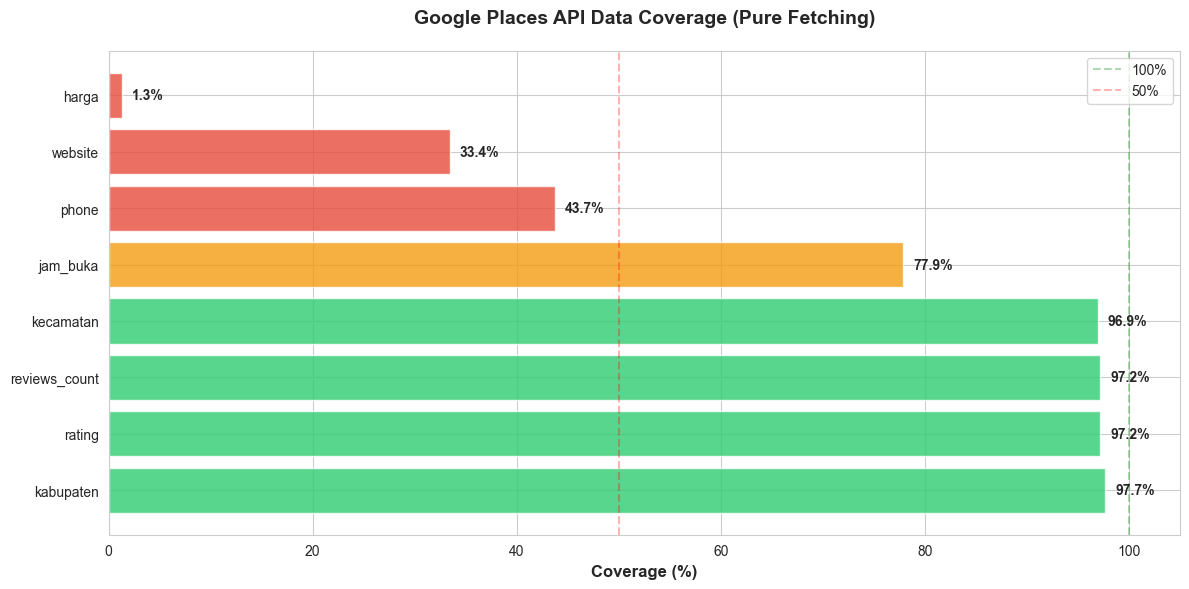


⚠️ NOTE: Low coverage for 'harga' (~1-5%) and partial for 'jam_buka' (~77%)
   This shows WHY enrichment was needed!


In [4]:
# Bar chart of Google API coverage
fig, ax = plt.subplots(figsize=(12, 6))

fields = coverage_df.index.tolist()
percentages = coverage_df['percentage'].tolist()
colors = ['#2ecc71' if p >= 90 else '#f39c12' if p >= 50 else '#e74c3c' for p in percentages]

bars = ax.barh(fields, percentages, color=colors, alpha=0.8)

for i, (bar, pct) in enumerate(zip(bars, percentages)):
    ax.text(pct + 1, bar.get_y() + bar.get_height()/2, 
            f'{pct:.1f}%', va='center', fontweight='bold')

ax.set_xlabel('Coverage (%)', fontsize=12, fontweight='bold')
ax.set_title('Google Places API Data Coverage (Pure Fetching)', 
             fontsize=14, fontweight='bold', pad=20)
ax.set_xlim(0, 105)
ax.axvline(x=100, color='green', linestyle='--', alpha=0.3, label='100%')
ax.axvline(x=50, color='red', linestyle='--', alpha=0.3, label='50%')
ax.legend()

plt.tight_layout()
plt.show()

print("\n⚠️ NOTE: Low coverage for 'harga' (~1-5%) and partial for 'jam_buka' (~77%)")
print("   This shows WHY enrichment was needed!")

## 1.5. Geographic Distribution from Google

DISTRIBUTION BY KABUPATEN (from Google API)
kabupaten
Kabupaten Sleman         87
Kabupaten Gunungkidul    79
Kabupaten Bantul         77
Kota Yogyakarta          67
Kabupaten Kulon Progo    52
Kabupaten Magelang        3
Kulon Progo Regency       2
Kabupaten Klaten          2
Bantul Regency            2
Kabupaten Wonogiri        1
Kabupaten Purworejo       1
Kabupaten Kediri          1
Yogyakarta City           1
Kulonprogo                1
Gunungkidul Regency       1
Kabupaten Wonosobo        1
Kabupaten Sukoharjo       1
Kabupaten Ngawi           1
Name: count, dtype: int64


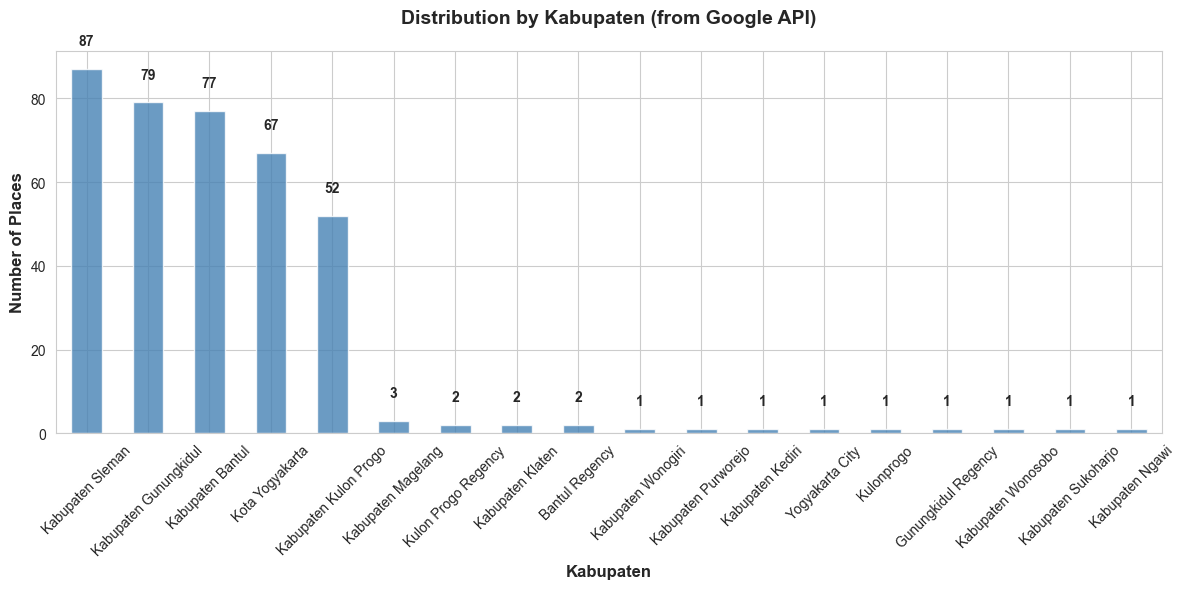

In [5]:
# Distribution by Kabupaten
if 'kabupaten' in df_google.columns:
    print("=" * 80)
    print("DISTRIBUTION BY KABUPATEN (from Google API)")
    print("=" * 80)
    
    kab_counts = df_google['kabupaten'].value_counts()
    print(kab_counts)
    
    # Visualization
    fig, ax = plt.subplots(figsize=(12, 6))
    kab_counts.plot(kind='bar', ax=ax, color='steelblue', alpha=0.8)
    ax.set_title('Distribution by Kabupaten (from Google API)', 
                 fontsize=14, fontweight='bold', pad=20)
    ax.set_xlabel('Kabupaten', fontsize=12, fontweight='bold')
    ax.set_ylabel('Number of Places', fontsize=12, fontweight='bold')
    ax.tick_params(axis='x', rotation=45)
    
    for i, v in enumerate(kab_counts):
        ax.text(i, v + 5, str(v), ha='center', va='bottom', fontweight='bold')
    
    plt.tight_layout()
    plt.show()

## 1.6. Rating Distribution from Google

RATING DATA FROM GOOGLE API
Places with rating: 378 (97.2%)

Rating statistics:
  Mean: 4.54
  Median: 4.50
  Min: 4.0
  Max: 5.0


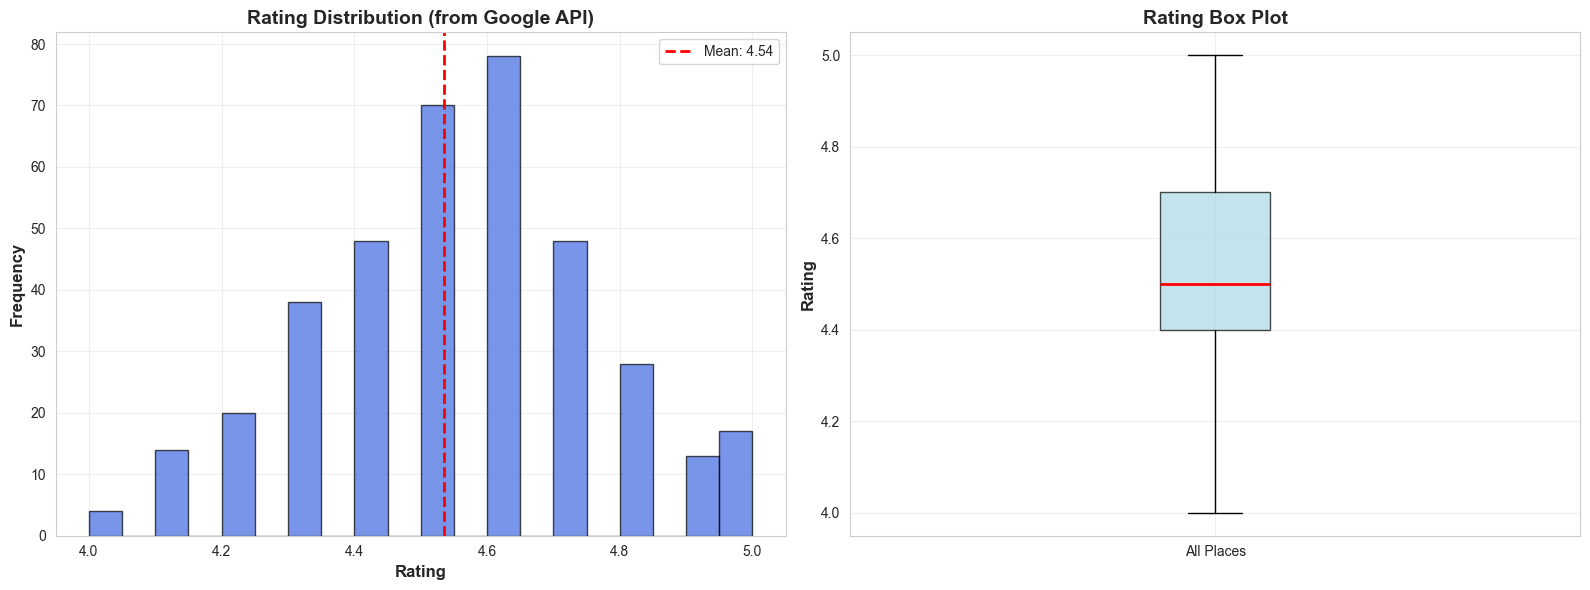

In [6]:
# Rating analysis
if 'rating' in df_google.columns:
    print("=" * 80)
    print("RATING DATA FROM GOOGLE API")
    print("=" * 80)
    
    ratings = df_google['rating'].dropna()
    
    print(f"Places with rating: {len(ratings)} ({len(ratings)/len(df_google)*100:.1f}%)")
    print(f"\nRating statistics:")
    print(f"  Mean: {ratings.mean():.2f}")
    print(f"  Median: {ratings.median():.2f}")
    print(f"  Min: {ratings.min():.1f}")
    print(f"  Max: {ratings.max():.1f}")
    
    # Distribution
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
    
    # Histogram
    ax1.hist(ratings, bins=20, color='royalblue', alpha=0.7, edgecolor='black')
    ax1.axvline(ratings.mean(), color='red', linestyle='--', linewidth=2, 
                label=f'Mean: {ratings.mean():.2f}')
    ax1.set_xlabel('Rating', fontsize=12, fontweight='bold')
    ax1.set_ylabel('Frequency', fontsize=12, fontweight='bold')
    ax1.set_title('Rating Distribution (from Google API)', fontsize=14, fontweight='bold')
    ax1.legend()
    ax1.grid(alpha=0.3)
    
    # Box plot
    ax2.boxplot(ratings, vert=True, patch_artist=True,
                boxprops=dict(facecolor='lightblue', alpha=0.7),
                medianprops=dict(color='red', linewidth=2))
    ax2.set_ylabel('Rating', fontsize=12, fontweight='bold')
    ax2.set_title('Rating Box Plot', fontsize=14, fontweight='bold')
    ax2.set_xticklabels(['All Places'])
    ax2.grid(alpha=0.3)
    
    plt.tight_layout()
    plt.show()

---
# PART 2: Intent Dataset Analysis (intents_diy_full.json)
---

## 2.1. Load Intent Dataset

In [7]:
# Load intents dataset
with open('../data/intents_diy_full.json', 'r', encoding='utf-8') as f:
    intents_data = json.load(f)

intents = intents_data['intents']

print("=" * 80)
print("INTENT DATASET LOADED")
print("=" * 80)
print(f"Total Intents: {len(intents)}")
print(f"\nFirst 10 intent tags:")
for i, intent in enumerate(intents[:10], 1):
    print(f"  {i}. {intent['tag']} ({len(intent['patterns'])} patterns)")

INTENT DATASET LOADED
Total Intents: 92

First 10 intent tags:
  1. greeting (21 patterns)
  2. pagi (6 patterns)
  3. siang (6 patterns)
  4. sore (6 patterns)
  5. malam (6 patterns)
  6. goodbye (18 patterns)
  7. help (14 patterns)
  8. fallback (10 patterns)
  9. provinsi_DIY (21 patterns)
  10. kabupaten_bantul (20 patterns)


## 2.2. Intent Categories Breakdown

In [8]:
# Categorize intents
categories = {
    'General': [],
    'Time-based Greetings': [],
    'Provinsi': [],
    'Kabupaten': [],
    'Kecamatan': []
}

for intent in intents:
    tag = intent['tag']
    
    if tag in ['greeting', 'goodbye', 'help', 'fallback']:
        categories['General'].append(intent)
    elif tag in ['pagi', 'siang', 'sore', 'malam']:
        categories['Time-based Greetings'].append(intent)
    elif tag == 'provinsi_DIY':
        categories['Provinsi'].append(intent)
    elif tag.startswith('kabupaten_') or tag == 'kota_yogyakarta':
        categories['Kabupaten'].append(intent)
    elif tag.startswith('kecamatan_'):
        categories['Kecamatan'].append(intent)

print("=" * 80)
print("INTENT CATEGORIES")
print("=" * 80)
for category, intent_list in categories.items():
    print(f"{category:25s}: {len(intent_list):3d} intents")

print(f"\n{'TOTAL':25s}: {sum(len(v) for v in categories.values()):3d} intents")

INTENT CATEGORIES
General                  :   4 intents
Time-based Greetings     :   4 intents
Provinsi                 :   1 intents
Kabupaten                :   5 intents
Kecamatan                :  78 intents

TOTAL                    :  92 intents


## 2.3. Visualization: Intent Distribution

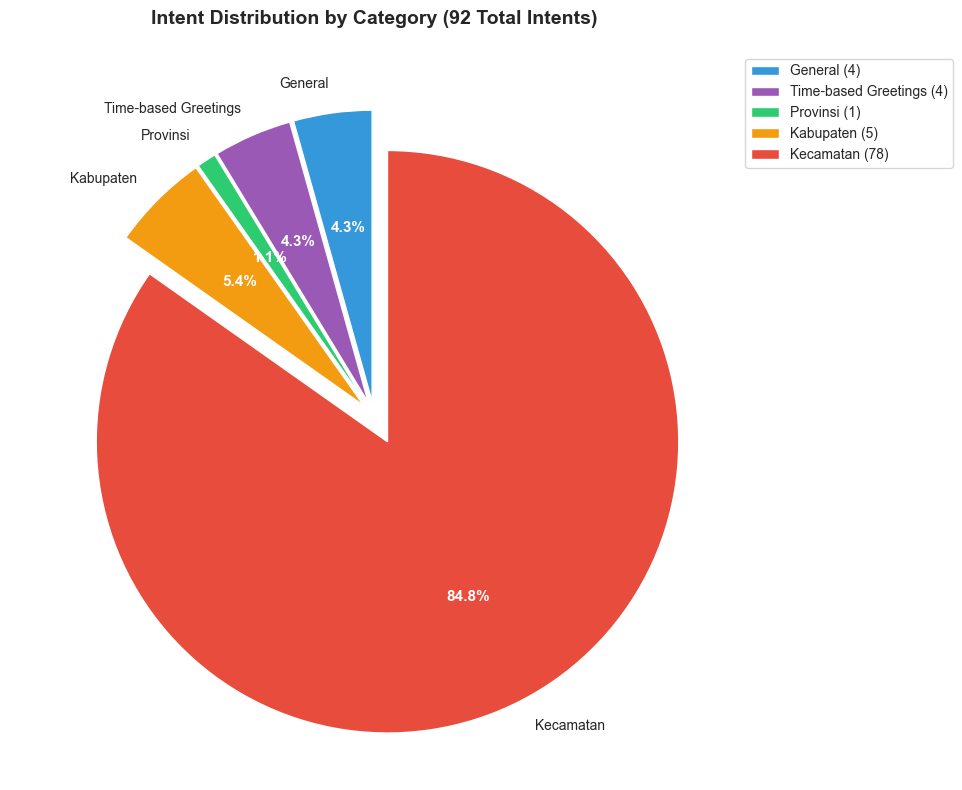

In [9]:
# Pie chart of intent categories
fig, ax = plt.subplots(figsize=(10, 8))

labels = list(categories.keys())
sizes = [len(v) for v in categories.values()]
colors = ['#3498db', '#9b59b6', '#2ecc71', '#f39c12', '#e74c3c']
explode = (0.05, 0.05, 0.05, 0.05, 0.1)

wedges, texts, autotexts = ax.pie(sizes, labels=labels, autopct='%1.1f%%',
                                    startangle=90, colors=colors, explode=explode)

for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_fontweight('bold')
    autotext.set_fontsize(11)

ax.set_title('Intent Distribution by Category (92 Total Intents)', 
             fontsize=14, fontweight='bold', pad=20)

# Add legend with counts
legend_labels = [f'{label} ({count})' for label, count in zip(labels, sizes)]
ax.legend(legend_labels, loc='upper left', bbox_to_anchor=(1, 1))

plt.tight_layout()
plt.show()

## 2.4. Pattern Statistics

In [10]:
# Calculate pattern statistics
pattern_counts = [len(intent['patterns']) for intent in intents]
response_counts = [len(intent['responses']) for intent in intents]

print("=" * 80)
print("PATTERN STATISTICS")
print("=" * 80)

total_patterns = sum(pattern_counts)
total_responses = sum(response_counts)

print(f"\nTotal Patterns: {total_patterns}")
print(f"Total Responses: {total_responses}")
print(f"\nPattern Statistics:")
print(f"  Mean patterns per intent: {np.mean(pattern_counts):.2f}")
print(f"  Median patterns per intent: {np.median(pattern_counts):.0f}")
print(f"  Min patterns: {min(pattern_counts)}")
print(f"  Max patterns: {max(pattern_counts)}")
print(f"\nResponse Statistics:")
print(f"  Mean responses per intent: {np.mean(response_counts):.2f}")
print(f"  Median responses per intent: {np.median(response_counts):.0f}")
print(f"  Min responses: {min(response_counts)}")
print(f"  Max responses: {max(response_counts)}")

PATTERN STATISTICS

Total Patterns: 1326
Total Responses: 102

Pattern Statistics:
  Mean patterns per intent: 14.41
  Median patterns per intent: 13
  Min patterns: 3
  Max patterns: 23

Response Statistics:
  Mean responses per intent: 1.11
  Median responses per intent: 1
  Min responses: 1
  Max responses: 4


## 2.5. Patterns per Category

PATTERNS PER CATEGORY
General                  :   63 patterns
Time-based Greetings     :   24 patterns
Provinsi                 :   21 patterns
Kabupaten                :  100 patterns
Kecamatan                : 1118 patterns


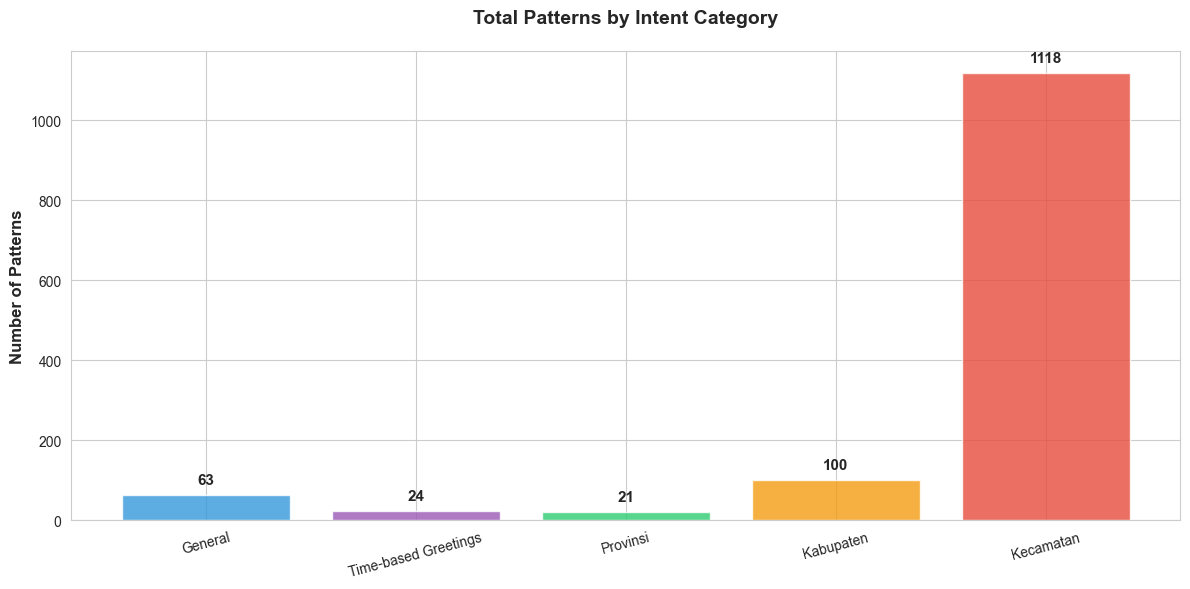

In [11]:
# Calculate patterns per category
category_patterns = {}
for category, intent_list in categories.items():
    total = sum(len(intent['patterns']) for intent in intent_list)
    category_patterns[category] = total

print("=" * 80)
print("PATTERNS PER CATEGORY")
print("=" * 80)
for category, count in category_patterns.items():
    print(f"{category:25s}: {count:4d} patterns")

# Visualization
fig, ax = plt.subplots(figsize=(12, 6))

cats = list(category_patterns.keys())
counts = list(category_patterns.values())
colors_bar = ['#3498db', '#9b59b6', '#2ecc71', '#f39c12', '#e74c3c']

bars = ax.bar(cats, counts, color=colors_bar, alpha=0.8)

for bar, count in zip(bars, counts):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height + 20,
            f'{count}',
            ha='center', va='bottom', fontweight='bold', fontsize=11)

ax.set_ylabel('Number of Patterns', fontsize=12, fontweight='bold')
ax.set_title('Total Patterns by Intent Category', 
             fontsize=14, fontweight='bold', pad=20)
ax.tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

## 2.6. General Intents Detail

In [12]:
# Show general intents in detail
print("=" * 80)
print("GENERAL INTENTS DETAIL")
print("=" * 80)

for intent in categories['General']:
    print(f"\nIntent: {intent['tag']}")
    print(f"  Patterns: {len(intent['patterns'])}")
    print(f"  Responses: {len(intent['responses'])}")
    print(f"  Sample patterns: {intent['patterns'][:3]}")
    print(f"  Sample response: {intent['responses'][0][:100]}...")

GENERAL INTENTS DETAIL

Intent: greeting
  Patterns: 21
  Responses: 2
  Sample patterns: ['halo bot', 'halo YOGA', 'selamat siang']
  Sample response: Halo! YOGA di sini, ada yang bisa saya bantu terkait wisata Yogyakarta?...

Intent: goodbye
  Patterns: 18
  Responses: 4
  Sample patterns: ['dadah', 'terima kasih', 'bye']
  Sample response: Sama-sama! Semoga rekomendasinya membantu ya....

Intent: help
  Patterns: 14
  Responses: 2
  Sample patterns: ['apa yang bisa kamu lakukan?', 'bisa bantu apa?', 'cara pakainya gimana?']
  Sample response: Saya bisa memberi rekomendasi wisata berdasarkan provinsi, kabupaten/kota, atau kecamatan di Yogyaka...

Intent: fallback
  Patterns: 10
  Responses: 2
  Sample patterns: ['?', 'ga ngerti', 'aku bingung']
  Sample response: Maaf, saya belum memahami itu. Coba sebutkan wilayah seperti kabupaten atau kecamatan ya!...


## 2.7. Time-based Greetings Detail

In [13]:
# Show time-based greetings in detail
print("=" * 80)
print("TIME-BASED GREETINGS DETAIL")
print("=" * 80)

for intent in categories['Time-based Greetings']:
    print(f"\nIntent: {intent['tag']}")
    print(f"  Patterns: {len(intent['patterns'])}")
    print(f"  Sample patterns: {intent['patterns']}")
    print(f"  Sample response: {intent['responses'][0]}")

TIME-BASED GREETINGS DETAIL

Intent: pagi
  Patterns: 6
  Sample patterns: ['selamat pagi YOGA', 'pagi', 'morning YOGA', 'morning', 'good morning', 'selamat pagi']
  Sample response: Selamat pagi juga! Ada yang bisa YOGA bantu?

Intent: siang
  Patterns: 6
  Sample patterns: ['selamat siang YOGA', 'siang', 'siang YOGA', 'afternoon', 'good afternoon', 'selamat siang']
  Sample response: Selamat siang juga! Ada yang bisa YOGA bantu?

Intent: sore
  Patterns: 6
  Sample patterns: ['selamat sore YOGA', 'sore', 'evening YOGA', 'good evening', 'evening', 'selamat sore']
  Sample response: Selamat sore juga! Ada yang bisa YOGA bantu?

Intent: malam
  Patterns: 6
  Sample patterns: ['selamat malam YOGA', 'malam', 'night YOGA', 'night', 'good night', 'selamat malam']
  Sample response: Selamat malam juga! Ada yang bisa YOGA bantu?


## 2.8. Location-based Intents Overview

In [14]:
# Kabupaten intents
print("=" * 80)
print("KABUPATEN INTENTS")
print("=" * 80)

for intent in categories['Kabupaten']:
    print(f"  {intent['tag']:30s}: {len(intent['patterns'])} patterns")

# Sample Kecamatan intents
print("\n" + "=" * 80)
print("KECAMATAN INTENTS (Sample - First 10)")
print("=" * 80)

for i, intent in enumerate(categories['Kecamatan'][:10], 1):
    print(f"  {i:2d}. {intent['tag']:35s}: {len(intent['patterns'])} patterns")

print(f"\n  ... and {len(categories['Kecamatan']) - 10} more kecamatan intents")

KABUPATEN INTENTS
  kabupaten_bantul              : 20 patterns
  kabupaten_gunungkidul         : 19 patterns
  kabupaten_kulonprogo          : 22 patterns
  kabupaten_sleman              : 21 patterns
  kota_yogyakarta               : 18 patterns

KECAMATAN INTENTS (Sample - First 10)
   1. kecamatan_bambanglipuro            : 19 patterns
   2. kecamatan_banguntapan              : 13 patterns
   3. kecamatan_bantul                   : 13 patterns
   4. kecamatan_berbah                   : 19 patterns
   5. kecamatan_cangkringan              : 19 patterns
   6. kecamatan_danurejan                : 13 patterns
   7. kecamatan_depok                    : 19 patterns
   8. kecamatan_dlingo                   : 13 patterns
   9. kecamatan_galur                    : 3 patterns
  10. kecamatan_gamping                  : 21 patterns

  ... and 68 more kecamatan intents


## 2.9. Pattern Distribution Histogram

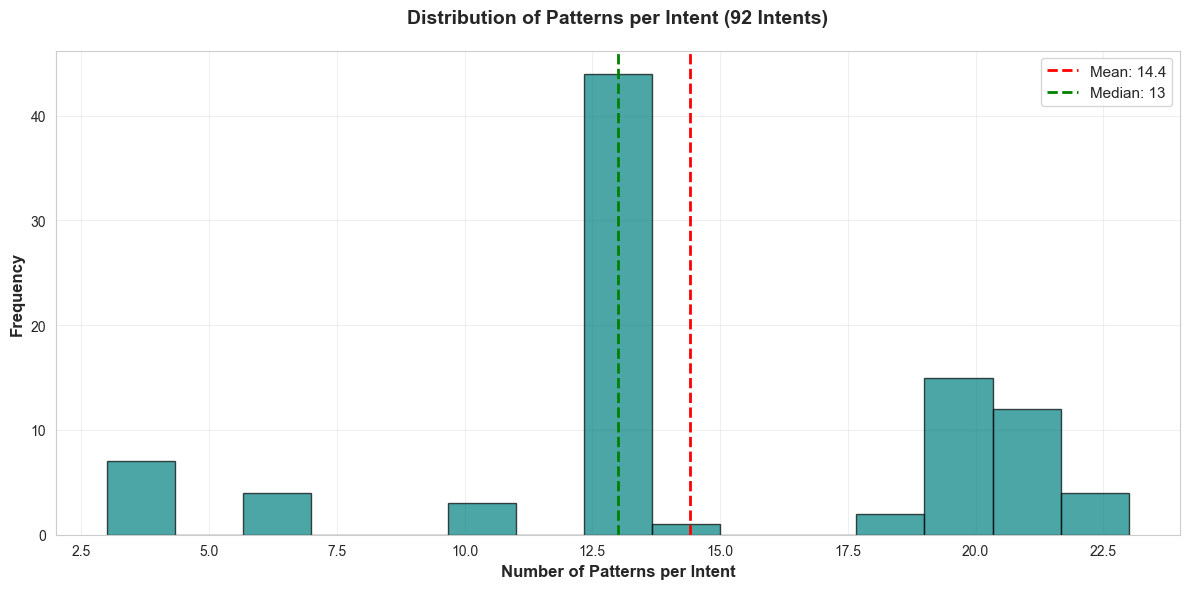

In [15]:
# Histogram of patterns per intent
fig, ax = plt.subplots(figsize=(12, 6))

ax.hist(pattern_counts, bins=15, color='teal', alpha=0.7, edgecolor='black')
ax.axvline(np.mean(pattern_counts), color='red', linestyle='--', linewidth=2,
           label=f'Mean: {np.mean(pattern_counts):.1f}')
ax.axvline(np.median(pattern_counts), color='green', linestyle='--', linewidth=2,
           label=f'Median: {np.median(pattern_counts):.0f}')

ax.set_xlabel('Number of Patterns per Intent', fontsize=12, fontweight='bold')
ax.set_ylabel('Frequency', fontsize=12, fontweight='bold')
ax.set_title('Distribution of Patterns per Intent (92 Intents)', 
             fontsize=14, fontweight='bold', pad=20)
ax.legend(fontsize=11)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 2.10. Top 10 Intents by Pattern Count

TOP 10 INTENTS BY PATTERN COUNT
   1. kecamatan_paliyan                       : 23 patterns
   2. kecamatan_saptosari                     : 23 patterns
   3. kecamatan_tepus                         : 23 patterns
   4. kabupaten_kulonprogo                    : 22 patterns
   5. greeting                                : 21 patterns
   6. provinsi_DIY                            : 21 patterns
   7. kabupaten_sleman                        : 21 patterns
   8. kecamatan_gamping                       : 21 patterns
   9. kecamatan_godean                        : 21 patterns
  10. kecamatan_kalasan                       : 21 patterns


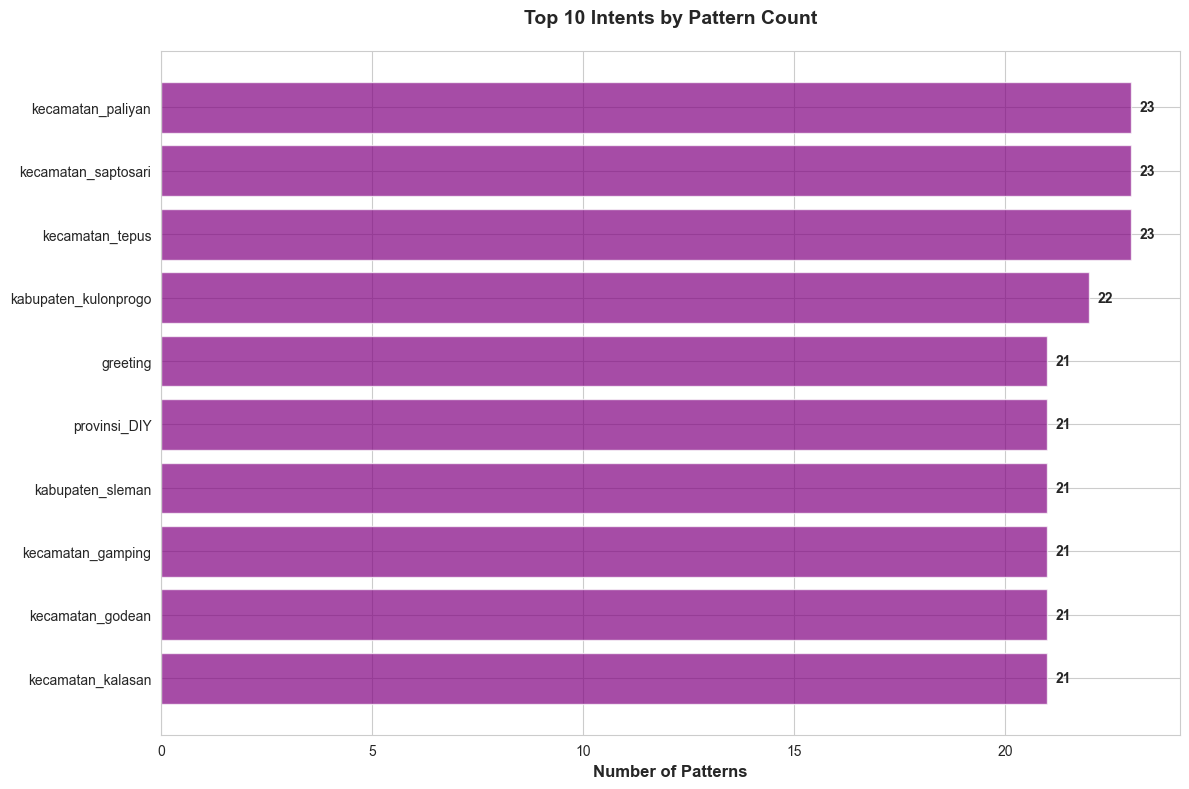

In [16]:
# Top 10 intents with most patterns
intent_pattern_map = [(intent['tag'], len(intent['patterns'])) for intent in intents]
intent_pattern_map.sort(key=lambda x: x[1], reverse=True)

top_10 = intent_pattern_map[:10]

print("=" * 80)
print("TOP 10 INTENTS BY PATTERN COUNT")
print("=" * 80)
for i, (tag, count) in enumerate(top_10, 1):
    print(f"  {i:2d}. {tag:40s}: {count} patterns")

# Visualization
fig, ax = plt.subplots(figsize=(12, 8))

tags = [t[0] for t in top_10]
counts = [t[1] for t in top_10]

ax.barh(tags, counts, color='purple', alpha=0.7)

for i, v in enumerate(counts):
    ax.text(v + 0.2, i, str(v), va='center', fontweight='bold')

ax.set_xlabel('Number of Patterns', fontsize=12, fontweight='bold')
ax.set_title('Top 10 Intents by Pattern Count', 
             fontsize=14, fontweight='bold', pad=20)
ax.invert_yaxis()

plt.tight_layout()
plt.show()

## 2.11. Context Set Analysis

In [17]:
# Check if all intents have context_set
print("=" * 80)
print("CONTEXT SET COVERAGE")
print("=" * 80)

with_context = sum(1 for intent in intents if 'context_set' in intent)
without_context = len(intents) - with_context

print(f"Intents with context_set: {with_context}/{len(intents)} ({with_context/len(intents)*100:.1f}%)")
print(f"Intents without context_set: {without_context}")

# Sample context_set
print("\n" + "=" * 80)
print("SAMPLE CONTEXT_SET VALUES")
print("=" * 80)

for intent in intents[:8]:
    if 'context_set' in intent:
        print(f"  {intent['tag']:20s}: {intent['context_set']}")

CONTEXT SET COVERAGE
Intents with context_set: 92/92 (100.0%)
Intents without context_set: 0

SAMPLE CONTEXT_SET VALUES
  greeting            : informasi seputar greeting dan sapaan kepada chatbot wisata
  pagi                : informasi seputar selamat pagi
  siang               : informasi seputar selamat siang
  sore                : informasi seputar selamat sore
  malam               : informasi seputar selamat malam
  goodbye             : informasi terkait goodbye terhadap chatbot wisata
  help                : informasi seputar bantuan dan fitur chatbot wisata Yogyakarta
  fallback            : informasi fallback untuk pertanyaan yang tidak dipahami chatbot


## 2.12. Sample Intent Showcase

In [18]:
# Show complete sample intent
print("=" * 80)
print("SAMPLE COMPLETE INTENT: greeting")
print("=" * 80)

greeting_intent = [i for i in intents if i['tag'] == 'greeting'][0]

print(f"\nTag: {greeting_intent['tag']}")
print(f"\nPatterns ({len(greeting_intent['patterns'])}):\n{greeting_intent['patterns']}")
print(f"\nResponses ({len(greeting_intent['responses'])}):\n{greeting_intent['responses']}")
print(f"\nContext Set:\n{greeting_intent.get('context_set', 'N/A')}")

SAMPLE COMPLETE INTENT: greeting

Tag: greeting

Patterns (21):
['halo bot', 'halo YOGA', 'selamat siang', 'permisi', 'hai chatbot wisata', 'selamat malam', 'hai', 'selamat pagi', 'halo', 'hai YOGA', 'hei', 'hi', 'hy', 'hello', 'halooo', 'haloo', 'haloo YOGA', 'hai bot', 'halo chatbot', 'permisi YOGA', 'halo YOGA bot']

Responses (2):
['Halo! YOGA di sini, ada yang bisa saya bantu terkait wisata Yogyakarta?', 'Hai! Apa yang bisa YOGA bantu untuk rekomendasi wisata Yogyakarta?']

Context Set:
informasi seputar greeting dan sapaan kepada chatbot wisata


---
# Summary & Conclusion
---

## Overall Summary

In [19]:
print("=" * 80)
print("OVERALL SUMMARY - YOGA CHATBOT DATASET")
print("=" * 80)

print("\n" + "="*80)
print("PART 1: Google Places API (Pure Fetching)")
print("="*80)
print(f"  Total places fetched: {len(df_google)}")
print(f"  Coverage:")
print(f"    - Rating: {coverage['rating']['percentage']:.1f}% (EXCELLENT)")
print(f"    - Jam Buka: {coverage['jam_buka']['percentage']:.1f}% (GOOD)")
print(f"    - Harga: {coverage['harga']['percentage']:.1f}% (POOR - enrichment needed)")
print(f"    - Geographic: {coverage['kabupaten']['percentage']:.1f}% (EXCELLENT)")

print("\n" + "="*80)
print("PART 2: Intent Dataset (intents_diy_full.json)")
print("="*80)
print(f"  Total intents: {len(intents)}")
print(f"  Total patterns: {sum(pattern_counts)}")
print(f"  Total responses: {sum(response_counts)}")
print(f"\n  Intent breakdown:")
for category, intent_list in categories.items():
    print(f"    - {category}: {len(intent_list)} intents")

print("\n" + "="*80)
print("KEY FEATURES")
print("="*80)
print("  ✓ Chatbot name: YOGA (YOgyakarta Guide Assistant)")
print("  ✓ Time-based greetings: pagi, siang, sore, malam")
print("  ✓ Context-aware: 100% intents have context_set")
print("  ✓ Enriched responses: jam buka & rating included")
print("  ✓ Multi-class classification: 92 classes")

print("\n" + "="*80)
print("NEXT STEPS")
print("="*80)
print("  1. ✓ Pattern Acquisition (DONE)")
print("  2. → Preprocessing (tokenization, padding, etc.)")
print("  3. → Feature Extraction (word embedding)")
print("  4. → LSTM Model Training")
print("  5. → Model Evaluation")
print("  6. → Deployment")

print("\n" + "="*80)
print("STATUS: ✓ Pattern Acquisition Complete - Ready for Preprocessing")
print("="*80)

OVERALL SUMMARY - YOGA CHATBOT DATASET

PART 1: Google Places API (Pure Fetching)
  Total places fetched: 389
  Coverage:
    - Rating: 97.2% (EXCELLENT)
    - Jam Buka: 77.9% (GOOD)
    - Harga: 1.3% (POOR - enrichment needed)
    - Geographic: 97.7% (EXCELLENT)

PART 2: Intent Dataset (intents_diy_full.json)
  Total intents: 92
  Total patterns: 1326
  Total responses: 102

  Intent breakdown:
    - General: 4 intents
    - Time-based Greetings: 4 intents
    - Provinsi: 1 intents
    - Kabupaten: 5 intents
    - Kecamatan: 78 intents

KEY FEATURES
  ✓ Chatbot name: YOGA (YOgyakarta Guide Assistant)
  ✓ Time-based greetings: pagi, siang, sore, malam
  ✓ Context-aware: 100% intents have context_set
  ✓ Enriched responses: jam buka & rating included
  ✓ Multi-class classification: 92 classes

NEXT STEPS
  1. ✓ Pattern Acquisition (DONE)
  2. → Preprocessing (tokenization, padding, etc.)
  3. → Feature Extraction (word embedding)
  4. → LSTM Model Training
  5. → Model Evaluation
  6. →